In [4]:
import os
import pandas as pd

# Directorios
input_dir = r"M:\material_isa\estadisticos\_Turberas\subset_sinSNOW_filtrMIN\Base de datos_Indices_filtrada\NDDI_filtr"
output_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI"
os.makedirs(output_dir, exist_ok=True)

# Función para normalizar nombres
def normalizar_nombre(nombre_archivo):
    base = nombre_archivo.replace("_sin_periodo_nieve_filtr_3_12.csv", "")
    return base.replace("_", "")

# Recorrer archivos
for archivo in os.listdir(input_dir):
    if archivo.endswith(".csv"):
        ruta = os.path.join(input_dir, archivo)
        try:
            df = pd.read_csv(ruta, sep=";", encoding="latin1")
            if "NDDI" not in df.columns or "FECHA" not in df.columns:
                print(f"⚠️ {archivo}: columnas necesarias no encontradas.")
                continue

            # Parsear fechas
            df['FECHA'] = df['FECHA'].astype(str).str.strip()
            df['FECHA_dt'] = pd.to_datetime(df['FECHA'], errors='coerce')
            df = df.dropna(subset=['FECHA_dt', 'NDDI'])

            # Agrupar por año-mes y calcular media
            df['YEAR_MES'] = df['FECHA_dt'].dt.to_period('M').astype(str)
            resumen = df.groupby('YEAR_MES')['NDDI'].mean().reset_index()
            resumen.columns = ['YEAR_MES', 'NDDI_MEDIA']

            # Guardar resultado
            nombre_turbera = normalizar_nombre(archivo)
            salida_csv = os.path.join(output_dir, f"NDDI_{nombre_turbera}_mensual.csv")
            resumen.to_csv(salida_csv, index=False, sep=";", encoding="utf-8")
            print(f"✅ Guardado: {salida_csv}")

        except Exception as e:
            print(f"❌ Error procesando {archivo}: {e}")

print("\n🎯 Todos los archivos procesados.")


✅ Guardado: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI\NDDI_BassaNera_mensual.csv
✅ Guardado: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI\NDDI_ClotsdeRialba_mensual.csv
✅ Guardado: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI\NDDI_Estanyeres_mensual.csv
✅ Guardado: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI\NDDI_PlandethHorn_mensual.csv
✅ Guardado: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI\NDDI_PladeSartari_mensual.csv
✅ Guardado: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI\NDDI_PletadeMolieres_mensual.csv

🎯 Todos los archivos procesados.


In [8]:
import os
import pandas as pd

# Directorios
input_dir = r"M:\material_isa\estadisticos\_Turberas\subset_sinSNOW_filtrMIN\Base de datos_Indices_filtrada\NDDI_filtr"
output_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI"
os.makedirs(output_dir, exist_ok=True)

# Función para normalizar nombres
def normalizar_nombre(nombre_archivo):
    base = nombre_archivo.replace("_sin_periodo_nieve_filtr_3_12.csv", "")
    return base.replace("_", "")

# Recorrer archivos
for archivo in os.listdir(input_dir):
    if archivo.endswith(".csv"):
        ruta = os.path.join(input_dir, archivo)
        try:
            df = pd.read_csv(ruta, sep=";", encoding="latin1")
            if "NDDI" not in df.columns or "FECHA" not in df.columns:
                print(f"⚠️ {archivo}: columnas necesarias no encontradas.")
                continue

            # Parsear fechas
            df['FECHA'] = df['FECHA'].astype(str).str.strip()
            df['FECHA_dt'] = pd.to_datetime(df['FECHA'], errors='coerce')
            df = df.dropna(subset=['FECHA_dt', 'NDDI'])

            # Agrupar por año y calcular media
            df['YEAR'] = df['FECHA_dt'].dt.year
            resumen = df.groupby('YEAR')['NDDI'].mean().reset_index()
            resumen.columns = ['YEAR', 'NDDI_MEDIA']

            # Guardar resultado
            nombre_turbera = normalizar_nombre(archivo)
            salida_csv = os.path.join(output_dir, f"NDDI_{nombre_turbera}_anual.csv")
            resumen.to_csv(salida_csv, index=False, sep=";", encoding="utf-8")
            print(f"✅ Guardado: {salida_csv}")

        except Exception as e:
            print(f"❌ Error procesando {archivo}: {e}")

print("\n🎯 Todos los archivos procesados.")


✅ Guardado: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI\NDDI_BassaNera_anual.csv
✅ Guardado: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI\NDDI_ClotsdeRialba_anual.csv
✅ Guardado: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI\NDDI_Estanyeres_anual.csv
✅ Guardado: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI\NDDI_PlandethHorn_anual.csv
✅ Guardado: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI\NDDI_PladeSartari_anual.csv
✅ Guardado: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI\NDDI_PletadeMolieres_anual.csv

🎯 Todos los archivos procesados.


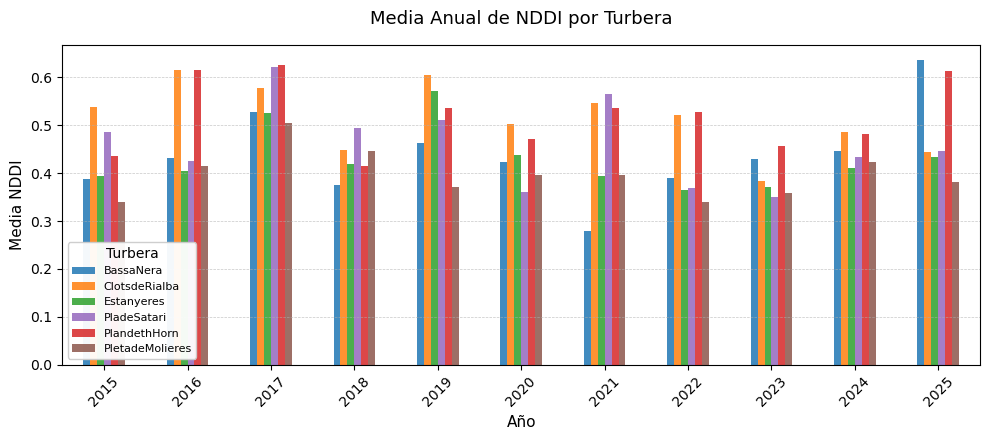

✅ Gráfico guardado en: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI\grafico_media_NDDI_turberas.png


In [12]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------
# Configuración de rutas
# ----------------------
input_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI"
output_path = os.path.join(input_dir, "grafico_media_NDDI_turberas.png")

# ----------------------
# Colores por turbera
# ----------------------
colores = {
    "BassaNera": "#1f77b4",
    "ClotsdeRialba": "#ff7f0e",
    "Estanyeres": "#2ca02c",
    "PladeSartari": "#9467bd",
    "PlandethHorn": "#d62728",
    "PletadeMolieres": "#8c564b"
}

# ----------------------
# Cargar CSVs y combinar
# ----------------------
dfs = []
for file in os.listdir(input_dir):
    if file.startswith("NDDI_") and file.endswith("_anual.csv"):
        nombre = file.replace("NDDI_", "").replace("_anual.csv", "")
        df = pd.read_csv(os.path.join(input_dir, file), sep=";")
        df["Turbera"] = nombre
        dfs.append(df)

df_total = pd.concat(dfs)

# Asegurarse de que los años sean enteros para orden correcto
df_total["YEAR"] = df_total["YEAR"].astype(int)

# Pivotear para tener turberas como columnas
pivot = df_total.pivot(index="YEAR", columns="Turbera", values="NDDI_MEDIA")

# ----------------------
# Crear gráfico de barras
# ----------------------
ax = pivot.plot(kind="bar", figsize=(10, 5),
                color=[colores.get(col, "#333333") for col in pivot.columns],
                alpha=0.85)

# Personalización
plt.title("Media Anual de NDDI por Turbera", fontsize=13, pad=15)
plt.xlabel("Año", fontsize=11)
plt.ylabel("Media NDDI", fontsize=11)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)

# Leyenda ajustada dentro del gráfico
plt.legend(title="Turbera", loc="upper left", bbox_to_anchor=(0, 0.4), fontsize=8, frameon=True, framealpha=0.95)

# Evitar cortes
plt.tight_layout(rect=[0, 0.1, 1, 1])

# Guardar
plt.savefig(output_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Gráfico guardado en: {output_path}")


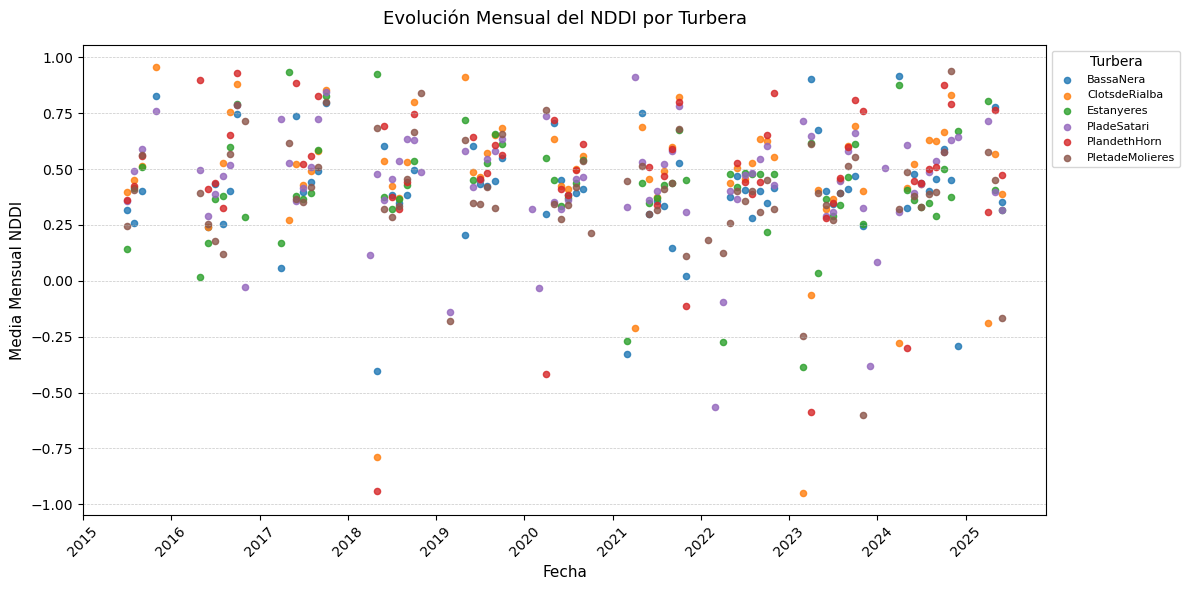

✅ Gráfico mensual (solo puntos) guardado en: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI\grafico_mensual_NDDI_turberas.png


In [20]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------
# Configuración de rutas
# ----------------------
input_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI"
output_path = os.path.join(input_dir, "grafico_mensual_NDDI_turberas.png")

# ----------------------
# Colores por turbera
# ----------------------
colores = {
    "BassaNera": "#1f77b4",
    "ClotsdeRialba": "#ff7f0e",
    "Estanyeres": "#2ca02c",
    "PladeSartari": "#9467bd",
    "PlandethHorn": "#d62728",
    "PletadeMolieres": "#8c564b"
}

# ----------------------
# Cargar CSVs y combinar
# ----------------------
dfs = []
for file in os.listdir(input_dir):
    if file.startswith("NDDI_") and file.endswith("_mensual.csv"):
        nombre = file.replace("NDDI_", "").replace("_mensual.csv", "")
        df = pd.read_csv(os.path.join(input_dir, file), sep=";")
        df["Turbera"] = nombre
        dfs.append(df)

df_total = pd.concat(dfs)

# Convertir columna a datetime para orden temporal
df_total["YEAR_MES"] = pd.to_datetime(df_total["YEAR_MES"], format="%Y-%m")

# ----------------------
# Crear gráfico de puntos
# ----------------------
plt.figure(figsize=(12, 6))
for nombre, grupo in df_total.groupby("Turbera"):
    plt.scatter(grupo["YEAR_MES"], grupo["NDDI_MEDIA"],
                s=20, alpha=0.8, label=nombre,
                color=colores.get(nombre, "#333333"))

# Personalización
plt.title("Evolución Mensual del NDDI por Turbera", fontsize=13, pad=15)
plt.xlabel("Fecha", fontsize=11)
plt.ylabel("Media Mensual NDDI", fontsize=11)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)

plt.legend(title="Turbera", loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout()

# Guardar
plt.savefig(output_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Gráfico mensual (solo puntos) guardado en: {output_path}")



In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------
# Configuración de rutas
# ----------------------
input_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI"
output_path = os.path.join(input_dir, "grafico_mensual_NDDI_turberas_LINEAS_PUNTOS.png")

# ----------------------
# Colores por turbera
# ----------------------
colores = {
    "BassaNera": "#1f77b4",
    "ClotsdeRialba": "#ff7f0e",
    "Estanyeres": "#2ca02c",
    "PladeSartari": "#9467bd",
    "PlandethHorn": "#d62728",
    "PletadeMolieres": "#8c564b"
}

# ----------------------
# Cargar CSVs y combinar
# ----------------------
dfs = []
for file in os.listdir(input_dir):
    if file.startswith("NDDI_") and file.endswith("_mensual.csv"):
        nombre = file.replace("NDDI_", "").replace("_mensual.csv", "")
        df = pd.read_csv(os.path.join(input_dir, file), sep=";")
        df["Turbera"] = nombre
        dfs.append(df)

df_total = pd.concat(dfs)

# Convertir columna a datetime para orden temporal
df_total["YEAR_MES"] = pd.to_datetime(df_total["YEAR_MES"], format="%Y-%m")

# ----------------------
# Crear gráfico de líneas con puntos
# ----------------------
plt.figure(figsize=(12, 6))
for nombre, grupo in df_total.groupby("Turbera"):
    grupo_ordenado = grupo.sort_values("YEAR_MES")
    plt.plot(grupo_ordenado["YEAR_MES"],
             grupo_ordenado["NDDI_MEDIA"],
             marker='o',  # punto
             linestyle='-',  # línea
             color=colores.get(nombre, "#333333"),
             label=nombre,
             alpha=0.9)

# Personalización
plt.title("Evolución Mensual del NDDI por Turbera (líneas y puntos)", fontsize=13, pad=15)
plt.xlabel("Fecha", fontsize=11)
plt.ylabel("Media Mensual NDDI", fontsize=11)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)

plt.legend(title="Turbera", loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout()

# Guardar
plt.savefig(output_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Gráfico mensual (líneas y puntos) guardado en: {output_path}")


✅ Gráfico mensual (líneas y puntos) guardado en: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDDI\grafico_mensual_NDDI_turberas_LINEAS_PUNTOS.png
